<span style="font-size: 30px;">Movie Data Analysis</span>

Our primary dataset comes from Kaggle's TMDB Movies Dataset, which contains information from approximately 930,000 movies. We will combine this dataset with IMDb ratings, Oscar diversity data, Rotten Tomatoes scores, and streaming service availability.

Each row in the primary TMDB dataset represents one movie with variables describing its characteristics, such as release date and ratings.

Key Variables Used: Production Companies, IMDb rating, TMDB rating, Gender, Rotten Tomatoes audience score, Rotten Tomatoes critic score, Streaming service, Movie title, Race, Winner

Data Sources: 
https://www.kaggle.com/datasets/asaniczka/tmdb-movies-dataset-2023-930k-movies

https://data.imdb.com/non-commercial-datasets/


In [44]:
df.head()

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
3,19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.932,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,The Avengers,When an unexpected enemy emerges and threatens...,98.082,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."


In [45]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 152686 entries, 0 to 152685
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    152686 non-null  int64  
 1   title                 152686 non-null  str    
 2   vote_average          152686 non-null  float64
 3   vote_count            152686 non-null  int64  
 4   status                152686 non-null  str    
 5   release_date          152395 non-null  str    
 6   revenue               152686 non-null  int64  
 7   runtime               152686 non-null  int64  
 8   adult                 152686 non-null  bool   
 9   backdrop_path         110880 non-null  str    
 10  budget                152685 non-null  float64
 11  homepage              26012 non-null   str    
 12  imdb_id               148977 non-null  str    
 13  original_language     152685 non-null  str    
 14  original_title        152685 non-null  str    
 15  overview   

In [48]:
imdb.info()

<class 'pandas.DataFrame'>
RangeIndex: 1726786 entries, 0 to 1726785
Data columns (total 3 columns):
 #   Column         Dtype  
---  ------         -----  
 0    tconst        str    
 1   averageRating  float64
 2   numVotes       int64  
dtypes: float64(1), int64(1), str(1)
memory usage: 39.5 MB


<span style="font-size: 20px;">Research Question #1</span>

What movie's features and production reflect the most on its generated profit (success)?

Description: A movie has many indicators for its success including users' / critics' ratings, production companies, genre and popularity, MPA rating, etc. To find the highest correlated and most explained features for the profitability of a movie, I will do a broad analysis of finding the most popular genres and pinpointing for which factors explain the profitability trend the most using multiple regression. Additionally, I intend to use machine learning to train a model to predict across more of the dataset to verify the trend. I expect the user-based rating features and production companies to be among movies with the most return. I intend to set up a bar graph with statistical significance bars to show the top 8 or so features and an array of scatterplots with lines of best fit to present the residual differences of the data against the line (i.e. R^2).

Of course, the dataset(s) will need to be cleaned and especially drop NaN values.

Recommendations:

Comparing user/critic ratings across websites + including LetterBoxd. Ex: cult classics (low critic / high user);
revenue/budget?
machine learning with training/test set

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

tmdb = pd.read_csv('data/tmdb_1.csv')

div = pd.read_csv('data/oscars_diversity.csv')

streaming = pd.read_csv('data/streaming.csv')

imdb = pd.read_csv('data/imdb_ratings.csv')

rt = pd.read_csv('data/rotten_tomatoes.csv')

In [23]:
tmdb.head()

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
3,19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.932,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,The Avengers,When an unexpected enemy emerges and threatens...,98.082,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."


In [24]:
tmdb.info()

<class 'pandas.DataFrame'>
RangeIndex: 152686 entries, 0 to 152685
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    152686 non-null  int64  
 1   title                 152686 non-null  str    
 2   vote_average          152686 non-null  float64
 3   vote_count            152686 non-null  int64  
 4   status                152686 non-null  str    
 5   release_date          152395 non-null  str    
 6   revenue               152686 non-null  int64  
 7   runtime               152686 non-null  int64  
 8   adult                 152686 non-null  bool   
 9   backdrop_path         110880 non-null  str    
 10  budget                152685 non-null  float64
 11  homepage              26012 non-null   str    
 12  imdb_id               148977 non-null  str    
 13  original_language     152685 non-null  str    
 14  original_title        152685 non-null  str    
 15  overview   

In [25]:
tmdb_numeric = tmdb[['vote_average','vote_count', 'revenue', 'runtime', 'adult', 'budget', 'popularity']]
tmdb_numeric['profit'] = tmdb_numeric['revenue'] - tmdb_numeric['budget']

In [26]:
tmdb_numeric['adult'] = tmdb_numeric['adult'].astype(int)
tmdb_numeric = tmdb_numeric.dropna()
y = tmdb_numeric['profit']
correlations = tmdb_numeric.corrwith(y)

for col, corr in correlations.items():
    print(f"{col} / profit Correlation: {corr:.4f}")

vote_average / profit Correlation: 0.0714
vote_count / profit Correlation: 0.7328
revenue / profit Correlation: 0.9775
runtime / profit Correlation: 0.0552
adult / profit Correlation: -0.0077
budget / profit Correlation: 0.6070
popularity / profit Correlation: 0.2144
profit / profit Correlation: 1.0000


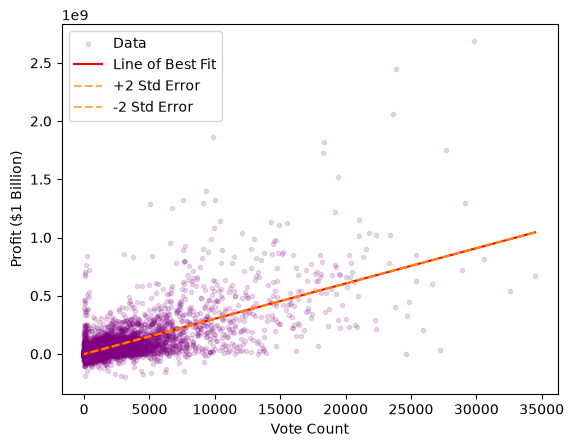

In [27]:
plt.scatter(tmdb_numeric['vote_count'], tmdb_numeric['profit'], marker='.', alpha=0.15, color = 'purple', label = 'Data')
plt.ylabel('Profit ($1 Billion)')
plt.xlabel('Vote Count');
model = LinearRegression()
y_vote = tmdb_numeric['profit']
X = np.array(tmdb_numeric['vote_count']).reshape(-1, 1)
model.fit(X, y_vote)
y_pred = model.predict(X)
from scipy.stats import linregress
slope, intercept, r_value, p_value, std_err = linregress(X.flatten(), y_vote)

plt.plot(X, y_pred, color='red', label = 'Line of Best Fit');
plt.plot(X, y_pred + 2 * std_err, color='darkorange', linestyle='--', alpha=0.7, label='+2 Std Error')
plt.plot(X, y_pred - 2 * std_err, color='darkorange', linestyle='--', alpha=0.7, label='-2 Std Error')
plt.legend()
plt.show()

In [28]:
X_count = tmdb_numeric[['vote_count']]

votecount_reg = LinearRegression()
votecount_reg.fit(X_count, y)

y_pred_count = votecount_reg.predict(X_count)

r2_count = r2_score(y_true = y, y_pred = y_pred_count)

print(f"R^2 from TMDB's Vote Count: {r2_count}")
#print(f"R^2 from All Features: {r2_all}")

R^2 from TMDB's Vote Count: 0.5369912835920504


Only about 54% of profit's variability would be explained by vote count if the model had OLS assumptions, however the major clustering and heteroskedasticity reject this. This is why 95% of the data does not fall within the two standard error lines within the visual above. So, a new model / way of finding the best feature needs to be utilized.

<span style="font-size: 20px;">Research Question 2</span>

Does racial/ gender diversity affect the number of awards that a movie wins?

In [29]:
tmdb = tmdb[['title','release_date','genres','status']]

In [30]:
movie_div = pd.merge(tmdb, div, how='left', left_on = 'title', right_on= 'film')
movie_div.head()


,title,release_date,genres,status,year_film,year_ceremony,ceremony,Category,gender,name,Race,film,winner
0,Inception,2010-07-15,"Action, Science Fiction, Adventure",Released,2010.0,2011.0,83.0,PRODUCTION DESIGN,Male,Production Design: Guy Hendrix Dyas; Set Decor...,White,Inception,False
1,Inception,2010-07-15,"Action, Science Fiction, Adventure",Released,2010.0,2011.0,83.0,CINEMATOGRAPHY,Male,Wally Pfister,White,Inception,True
2,Inception,2010-07-15,"Action, Science Fiction, Adventure",Released,2010.0,2011.0,83.0,MUSIC (Original Score),Male,Hans Zimmer,White,Inception,False
3,Inception,2010-07-15,"Action, Science Fiction, Adventure",Released,2010.0,2011.0,83.0,BEST PICTURE,Female,"Emma Thomas and Christopher Nolan, Producers",White,Inception,False
4,Inception,2010-07-15,"Action, Science Fiction, Adventure",Released,2010.0,2011.0,83.0,SOUND EDITING,Male,Richard King,White,Inception,True


In [31]:
movie_div['release_date'] = pd.to_datetime(movie_div['release_date'])

Since the Screen Actors Guild was founded in 1933, I will only use data from then onward, as the lack of POC data might affect the analysis. To do this, I will convert the release date column into a datetime object instead of a string

In [32]:
movie_div = movie_div[(movie_div['release_date'] >= '1930-06-30') & (movie_div['winner'] == True)]

Now I want to see both the racial distribution of winners, as well as gender

gender
Male      2533
Female     691
Name: count, dtype: int64

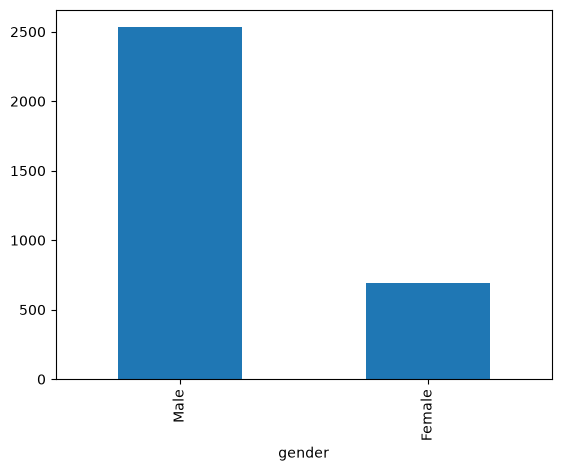

In [33]:
movie_div['gender'] = movie_div['gender'].str.capitalize()
movie_gender_wins = movie_div['gender'].value_counts()
movie_gender_wins.plot(kind="bar")

movie_div['gender'].value_counts()


Race
White       3070
Asian         75
Black         65
Hispanic      14
Name: count, dtype: int64

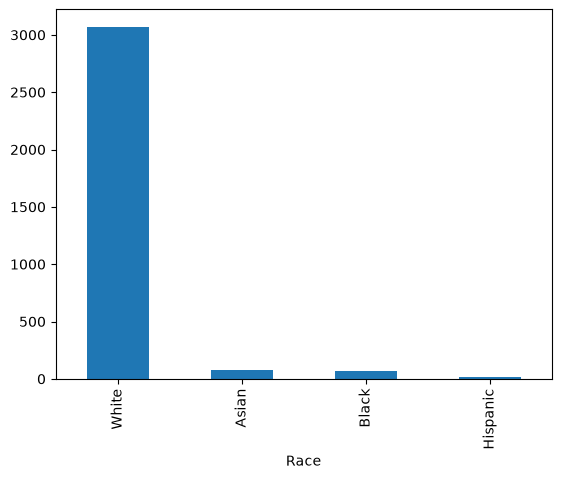

In [34]:
movie_race = movie_div['Race'].value_counts()
movie_race.plot(kind = "bar")

movie_div['Race'].value_counts()

Since the creation of the Screen Actors Guild, far more male winners have been elected than female winners, with 2533 wins. In the case of race, there have been far more white winners, with a total of 3070

<span style="font-size: 20px;">Research Question 3</span>


Do movie ratings systematically differ between websites, and how do these differences vary across streaming services?

Hypothesis: Movie ratings will will differ between IMDb, TMDB, and Rotten Tomatoes. I also expect these differences to vary across streaming services because each service has a different mix of movies and audiences.

Variables Used: IMDb rating, TMDB rating, Rotten Tomatoes audience score, Rotten Tomatoes critic score, Streaming service, Movie title

In [36]:
import pandas as pd

df = pd.read_csv("data/tmdb_1.csv")
df.shape

(152686, 24)

In [38]:
df.head()

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
3,19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.932,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,The Avengers,When an unexpected enemy emerges and threatens...,98.082,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."


In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 152686 entries, 0 to 152685
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    152686 non-null  int64  
 1   title                 152686 non-null  str    
 2   vote_average          152686 non-null  float64
 3   vote_count            152686 non-null  int64  
 4   status                152686 non-null  str    
 5   release_date          152395 non-null  str    
 6   revenue               152686 non-null  int64  
 7   runtime               152686 non-null  int64  
 8   adult                 152686 non-null  bool   
 9   backdrop_path         110880 non-null  str    
 10  budget                152685 non-null  float64
 11  homepage              26012 non-null   str    
 12  imdb_id               148977 non-null  str    
 13  original_language     152685 non-null  str    
 14  original_title        152685 non-null  str    
 15  overview   

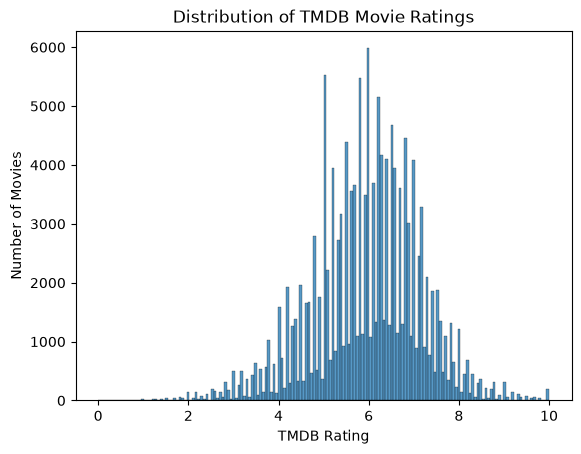

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x='vote_average')

plt.title('Distribution of TMDB Movie Ratings')
plt.xlabel('TMDB Rating')
plt.ylabel('Number of Movies')
plt.show()

This histogram shows the distribution of TMDB movie ratings across the dataset. Most movies appear to have a rating between 5-7 with a high concentration around 6.

I will merge the TMDB dataset with IMDb and Rotten Tomatoes rating data using movie identifiers, then add streaming service information. For my analysis, I plan to use boxplots to compare rating distributions across websites and across streaming services. I will then investigate a regression model that includes website, streaming service, and their interaction to test whether rating differences vary across services.